In [1]:
# Import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 50)

# Paths to our raw data files
RAW_LAND = "../../data/raw/cbsl_land_dataset.csv"
RAW_LVI = "../../data/raw/cbsl_half_yearly_dataset.xls"

print("pandas version:", pd.__version__)


pandas version: 3.0.5


In [ ]:
# Load the land dataset (real data, calibrated to CBSL LVI)
land = pd.read_csv(RAW_LAND)

# How many rows and columns?
print("Shape (rows, columns):", land.shape)

# Show the first 5 rows
land.head()


Shape (rows, columns): (6000, 35)


,Address_ID,Address,Land_size(Perches),Price_Scale,Land_type,Posted_Date_new,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Mentioned Price(Rs),Price per Perch
0,18,bope,10.0,per perch,Residential,2023-08-13,36.09,0,18.656149,1,0.546813,0,10.478451,0,21.224113,0,5.192049,16.694409,3.421132,4.421975,0,4.385422,0,15.857647,0,4.668703,0,11.631035,0,4.992931,0,9.219190,0,3050000.0,305000.0
1,10,thalawathugoda,27.0,per perch,"Commercial, Residential",2025-02-15,14.19,0,3.947032,1,1.741785,0,3.685223,0,2.039184,0,4.333994,4.620078,3.239813,0.047188,14,0.311696,1,4.725444,0,0.346662,1,2.606001,0,0.207307,9,1.832361,1,84942000.0,3146000.0
2,19,boralesgamuwa,17.5,per perch,"Commercial, Residential",2021-09-16,13.98,0,4.016691,1,0.429339,0,2.727913,0,3.818289,1,1.440498,8.830429,2.212403,0.071858,10,0.087264,2,1.864090,1,4.973745,0,0.811285,1,0.100747,11,0.886449,1,59255000.0,3386000.0
3,23,kirulapone,16.0,per perch,Residential,2021-11-20,8.43,6,0.939434,9,0.601618,4,0.555210,6,0.529896,5,0.683795,8.270892,1.393860,0.062262,43,0.107440,11,1.478614,1,1.066323,6,1.082209,3,0.220060,23,0.776472,5,81536000.0,5096000.0
4,33,rajagiriya,51.0,per perch,"Commercial, Residential, Other",2023-10-14,8.66,1,1.756311,7,0.641319,0,2.032610,1,0.708394,1,0.549898,5.213416,1.366903,0.064668,9,0.459100,2,1.512528,1,0.842420,3,0.120769,3,0.050658,13,2.104233,0,172329000.0,3379000.0


In [3]:
# Column names, data types and non-null counts
land.info()

# Count missing values in each column (only show columns that have some)
missing = land.isna().sum()
print("\nColumns with missing values:")
print(missing[missing > 0])

# Count fully duplicated rows
print("\nDuplicate rows:", land.duplicated().sum())



<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Address_ID                         6000 non-null   int64  
 1   Address                            6000 non-null   str    
 2   Land_size(Perches)                 6000 non-null   float64
 3   Price_Scale                        6000 non-null   str    
 4   Land_type                          6000 non-null   str    
 5   Posted_Date_new                    6000 non-null   str    
 6   Distance from fort                 6000 non-null   float64
 7   count_govtschools_A                6000 non-null   int64  
 8   min_dist_govtschools_a             6000 non-null   float64
 9   count_govtschools_B                6000 non-null   int64  
 10  min_dist_govtschools_b             6000 non-null   float64
 11  count_semigovtschools              6000 non-null   int64  
 12  min

count    6.000000e+03
mean     2.512594e+06
std      4.065911e+06
min      1.000000e+05
25%      6.050000e+05
50%      1.151000e+06
75%      2.970500e+06
max      1.142950e+08
Name: Price per Perch, dtype: float64


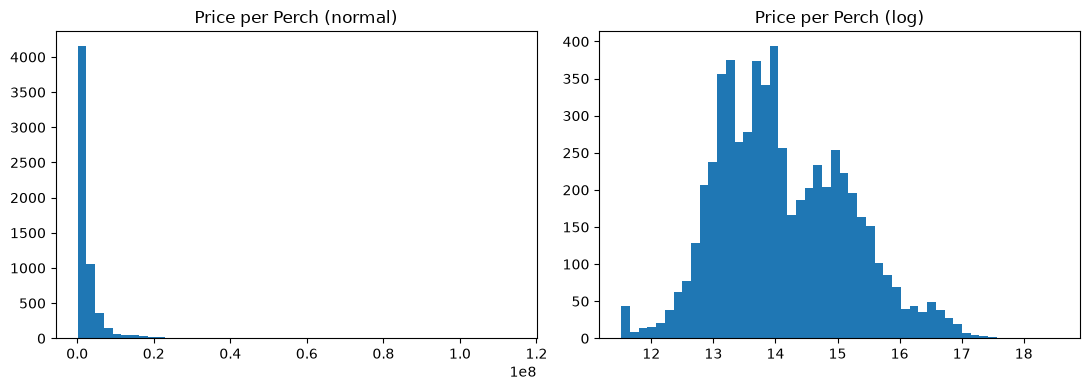

In [4]:
# Summary numbers of the target column
print(land["Price per Perch"].describe())

# Plot the price: normal scale and log scale side by side
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(land["Price per Perch"], bins=50)
ax[0].set_title("Price per Perch (normal)")

ax[1].hist(np.log(land["Price per Perch"]), bins=50)
ax[1].set_title("Price per Perch (log)")

plt.tight_layout()
plt.show()


In [5]:
# How many rows sit exactly at the minimum price?
print("Rows at Rs 100,000:", (land["Price per Perch"] == 100000).sum())

# Number of unique areas
print("Unique areas:", land["Address_ID"].nunique())

# Land types and how many rows each has
print("\nLand types:")
print(land["Land_type"].value_counts())

# Date range of the listings
dates = pd.to_datetime(land["Posted_Date_new"])
print("\nDate range:", dates.min().date(), "to", dates.max().date())

# Land size summary
print("\nLand size (perches):")
print(land["Land_size(Perches)"].describe())


Rows at Rs 100,000: 39
Unique areas: 154

Land types:
Land_type
Residential                                     3047
Commercial, Residential                         1448
Commercial, Residential, Other                   726
Residential, Other                               355
Commercial                                       164
Agricultural, Commercial, Residential            101
Agricultural, Commercial, Residential, Other      90
Other                                             30
Agricultural, Residential                         12
Commercial, Other                                 11
Agricultural                                       6
Agricultural, Residential, Other                   6
Agricultural, Commercial, Other                    3
Agricultural, Commercial                           1
Name: count, dtype: int64

Date range: 2021-01-01 to 2025-12-30

Land size (perches):
count    6000.000000
mean       16.083922
std        26.172007
min         1.000000
25%         7.000000
50%

In [6]:
# Look at the rows with the minimum price
floor = land[land["Price per Perch"] == 100000]
print("Floor rows by area (top 10):")
print(floor["Address"].value_counts().head(10))

# Look at the biggest land sizes
cols = ["Address", "Land_size(Perches)", "Land_type", "Price_Scale",
        "Mentioned Price(Rs)", "Price per Perch"]
print("\nLargest land sizes:")
print(land.sort_values("Land_size(Perches)", ascending=False)[cols].head(8))

# How many listings are in 2025-H2 (LVI not published yet)?
dates = pd.to_datetime(land["Posted_Date_new"])
print("\nRows in 2025-H2:", (dates >= "2025-07-01").sum())

# Rows per year
print("\nRows per year:")
print(dates.dt.year.value_counts().sort_index())


Floor rows by area (top 10):
Address
ranala          10
meegoda          8
avissawella      5
werahera         4
piliyandala      3
kesbewa          2
kosgama          2
oruwala          1
athurugiriya     1
padukka          1
Name: count, dtype: int64

Largest land sizes:
            Address  Land_size(Perches)  \
4341        padukka               454.0   
5200  mount lavinia               409.0   
2438  mount lavinia               409.0   
2345  mount lavinia               409.0   
4795  mount lavinia               409.0   
3239  mount lavinia               403.0   
969   mount lavinia               403.0   
4272  mount lavinia               403.0   

                                  Land_type  Price_Scale  Mentioned Price(Rs)  \
4341  Agricultural, Commercial, Residential  total price         4.540000e+07   
5200                Commercial, Residential    per perch         1.147245e+09   
2438                Commercial, Residential    per perch         1.510437e+09   
2345          

     period  Overall  Residential  Commercial  Industrial
0   2017-H1    100.0        100.0       100.0       100.0
1   2017-H2    107.0        106.8       107.0       107.2
2   2018-H1    114.7        114.3       114.7       115.1
3   2018-H2    122.3        121.7       121.5       123.7
4   2019-H1    129.7        128.9       128.5       131.5
5   2019-H2    137.2        136.6       135.5       139.4
6   2020-H1    144.3        144.9       142.0       146.1
7   2020-H2    151.6        152.0       148.7       154.1
8   2021-H1    159.8        159.3       158.7       161.3
9   2021-H2    178.7        176.3       173.4       186.6
10  2022-H1    186.9        183.4       182.8       194.6
11  2022-H2    205.2        203.1       200.5       212.0
12  2023-H1    215.3        215.0       210.3       220.7
13  2023-H2    219.8        221.0       214.0       224.5
14  2024-H1    230.1        233.3       228.1       228.9
15  2024-H2    236.8        242.9       234.1       233.2
16  2025-H1   

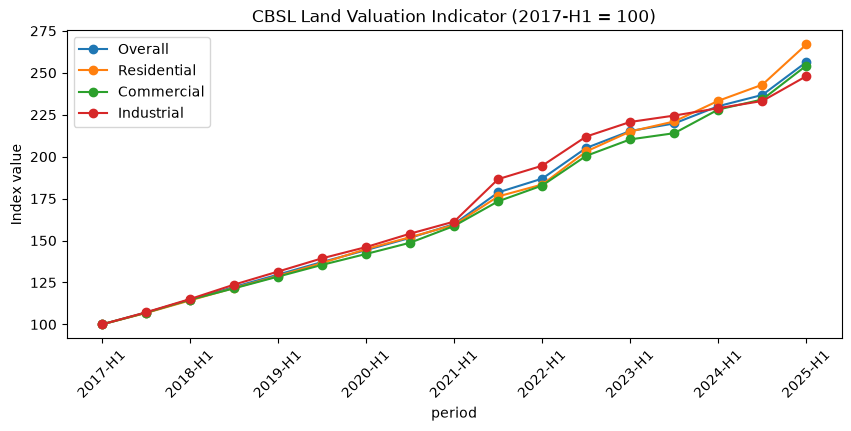

In [7]:
# Make the src folder importable, then load the LVI table
import sys
sys.path.append("../../src")
from load_cbsl import load_lvi_half_yearly

lvi = load_lvi_half_yearly(RAW_LVI)
print(lvi)

# Plot the four LVI series
lvi.set_index("period")[["Overall", "Residential", "Commercial", "Industrial"]].plot(
    figsize=(10, 4), marker="o", title="CBSL Land Valuation Indicator (2017-H1 = 100)")
plt.xticks(rotation=45)
plt.ylabel("Index value")
plt.show()


## Summary of Data Understanding

- Land data: 6,000 rows, 35 columns, 154 areas, Jan 2021 to Dec 2025.
  This is real data, calibrated to the CBSL Land Valuation Indicator.
- No missing values and no duplicate rows.
- Price per Perch is right-skewed, so we will use log(price) as the target.
- High prices (up to Rs 114M, Kollupitiya) are real prime-area prices. They are checked, not deleted.
- 39 rows sit at the Rs 100,000 floor (outskirt areas). Kept, but noted.
- Land_type has mixed labels (e.g. "Commercial, Residential"). We will turn them into 4 yes/no flags.
- 624 rows are in 2025-H2, where LVI is not published yet.
- CBSL LVI: 17 half-yearly values (2017-H1 to 2025-H1), steady upward trend.
- Next: Notebook 02 (data preparation).
